# Flood Mapping with Sentinel-1 SAR: Upper Assam, July 2026
### GeoAI Professional Program | OrbitalIQ Analytics
**Part B: Analysis in JupyterLab**

In July 2026, a cloudburst over the Nagaland hills (18–20 July) sent the Disang, Dikhow, Jhanji and other rivers into Upper Assam. Sivasagar, Charaideo and Jorhat, districts with little history of high floods, were among the worst hit.

In Part A we downloaded Sentinel-1 radar images from Google Earth Engine. Now we will:

1. Load and explore the pre-flood and flood images
2. Reduce speckle noise
3. Detect flooded pixels with **change detection**
4. Clean the result with supporting layers
5. Calculate **flooded area** and **flooded cropland**
6. Make a final flood map and save the results

**Key idea:** calm water reflects radar energy away from the satellite, so it looks **dark** (low backscatter). Land that suddenly becomes dark between the two dates has most likely flooded.

## 0. Setup

In [5]:
# Run once if a library is missing:
# !pip install rioxarray scikit-image geopandas matplotlib pandas
#%pip install rioxarray
%pip install scikit-image
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import rioxarray as rxr
from scipy import ndimage
from skimage.filters import threshold_otsu

# Files exported from GEE (Part A). Keep them next to this notebook.
PRE_FILE  = "assam_s1_pre.tif"
POST_FILE = "assam_s1_post.tif"
AUX_FILE  = "assam_aux.tif"

OUT_DIR = "flood_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

plt.rcParams["figure.dpi"] = 110

   ---------------------------------------- 0.0/11.9 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.9 MB 5.2 MB/s eta 0:00:03
   ------------- -------------------------- 3.9/11.9 MB 15.5 MB/s eta 0:00:01
   ---------------------- ----------------- 6.6/11.9 MB 14.2 MB/s eta 0:00:01
   ------------------------------ --------- 9.2/11.9 MB 12.9 MB/s eta 0:00:01
   -------------------------------------- - 11.5/11.9 MB 12.3 MB/s eta 0:00:01
   ---------------------------------------- 11.9/11.9 MB 10.8 MB/s  0:00:01
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------  2.1/2.1 MB 10.9 MB/s eta 0:00:01
   ---------------------------------------- 2.1/2.1 MB 8.8 MB/s  0:00:00

   ---------------------------------------- 0/5 [tifffile]
   ---------------------------------------- 0/5 [tifffile]
   ---------------------------------------- 0/5 [tifffile]
   ---------------------------------------- 0/5 [tifffile]
   -----

## 1. Load the data

Each SAR file has two bands: **band 1 = VV**, **band 2 = VH**, in decibels (dB).
The supporting file has: **band 1 = JRC water occurrence (%)**, **band 2 = ESA WorldCover class**, **band 3 = slope (degrees)**.

In [6]:
pre  = rxr.open_rasterio(PRE_FILE,  masked=True)
post = rxr.open_rasterio(POST_FILE, masked=True)
aux  = rxr.open_rasterio(AUX_FILE,  masked=True)

# Make sure every layer sits on exactly the same pixel grid as the pre-flood image
post = post.rio.reproject_match(pre)
aux  = aux.rio.reproject_match(pre)

print("CRS        :", pre.rio.crs)
print("Shape      :", pre.shape, "(bands, rows, cols)")
res = pre.rio.resolution()
PIXEL_AREA = abs(res[0] * res[1])          # m² per pixel
print("Pixel size :", abs(res[0]), "m  ->", PIXEL_AREA, "m² per pixel")

pre_vv,  pre_vh  = pre.sel(band=1).values,  pre.sel(band=2).values
post_vv, post_vh = post.sel(band=1).values, post.sel(band=2).values
jrc   = aux.sel(band=1).values
lc    = aux.sel(band=2).values
slope = aux.sel(band=3).values

valid = np.isfinite(pre_vv) & np.isfinite(post_vv)
print(f"Valid pixels: {valid.sum():,} of {valid.size:,}")

# Map extent in km (for axis labels)
xmin, ymin, xmax, ymax = pre.rio.bounds()
EXTENT = [xmin/1000, xmax/1000, ymin/1000, ymax/1000]

CRS        : EPSG:32646
Shape      : (2, 2554, 4750) (bands, rows, cols)
Pixel size : 20.0 m  -> 400.0 m² per pixel
Valid pixels: 11,766,601 of 12,131,500


## 2. Before vs after: what does the radar see?

Bright = strong backscatter (rough land, vegetation, buildings). Dark = weak backscatter (smooth water).

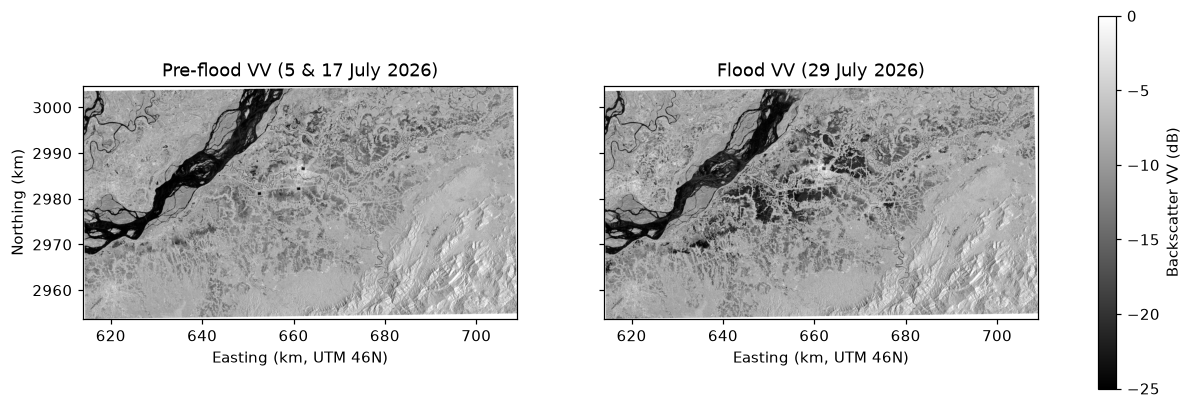

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for ax, img, title in zip(axes, [pre_vv, post_vv],
                          ["Pre-flood VV (5 & 17 July 2026)", "Flood VV (29 July 2026)"]):
    im = ax.imshow(img, cmap="gray", vmin=-25, vmax=0, extent=EXTENT)
    ax.set_title(title)
    ax.set_xlabel("Easting (km, UTM 46N)")
axes[0].set_ylabel("Northing (km)")
fig.colorbar(im, ax=axes, shrink=0.8, label="Backscatter VV (dB)")
plt.savefig(f"{OUT_DIR}/01_pre_vs_post.png", dpi=200, bbox_inches="tight")
plt.show()

### Change composite
Red = pre-flood, Green and Blue = flood image.
Land that was bright before and dark during the flood shows up **red**. Areas that stayed the same look grey.

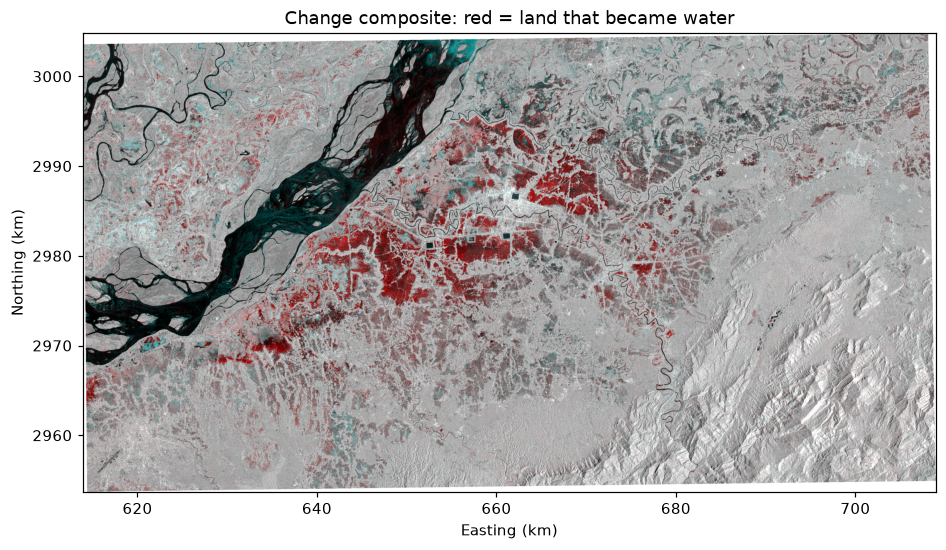

In [8]:
def to01(db, lo=-25, hi=0):
    return np.clip((db - lo) / (hi - lo), 0, 1)

rgb = np.dstack([to01(pre_vv), to01(post_vv), to01(post_vv)])
rgb[~valid] = 1

plt.figure(figsize=(10, 5.5))
plt.imshow(rgb, extent=EXTENT)
plt.title("Change composite: red = land that became water")
plt.xlabel("Easting (km)"); plt.ylabel("Northing (km)")
plt.savefig(f"{OUT_DIR}/02_change_rgb.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. Histogram: why thresholding works

If an image has both water and land, its histogram usually shows **two humps**: a dark one (water) and a bright one (land). The valley between them is a natural place to split water from land.

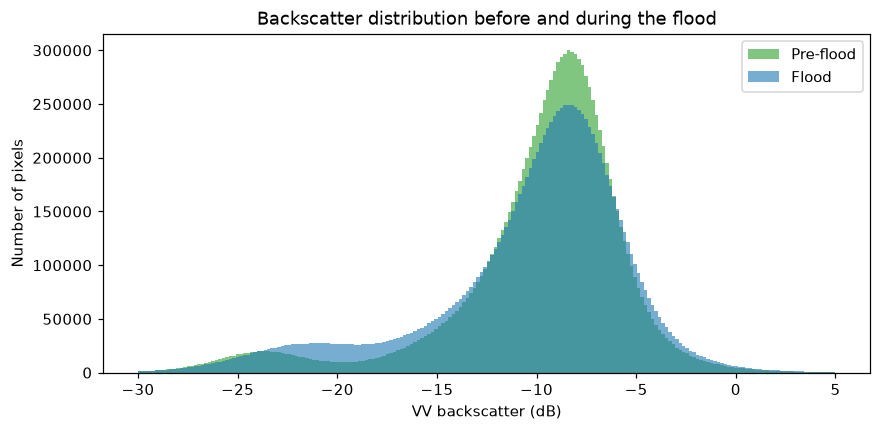

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(pre_vv[valid],  bins=200, range=(-30, 5), alpha=0.6, label="Pre-flood",  color="tab:green")
ax.hist(post_vv[valid], bins=200, range=(-30, 5), alpha=0.6, label="Flood",      color="tab:blue")
ax.set_xlabel("VV backscatter (dB)"); ax.set_ylabel("Number of pixels")
ax.set_title("Backscatter distribution before and during the flood")
ax.legend()
plt.show()

## 4. Speckle filtering

SAR images have a grainy "salt and pepper" texture called **speckle**. It comes from many small scatterers inside each pixel interfering with each other. It is not real detail, so we reduce it before classification.

We use the **Lee filter**: it smooths flat, uniform areas strongly but keeps edges (like river banks) sharp. Filtering is done on linear power values, not dB.

In [10]:
def lee_filter(img_db, size=5, enl=4.4):
    """Lee speckle filter.
    img_db : 2-D array in dB (NaN = no data)
    size   : moving window size in pixels
    enl    : equivalent number of looks (~4.4 for Sentinel-1 IW GRD)
    """
    lin = np.power(10.0, img_db / 10.0)          # dB -> linear power
    ok = np.isfinite(lin)
    z = np.where(ok, lin, 0.0)

    with np.errstate(invalid="ignore", divide="ignore"):
        n     = ndimage.uniform_filter(ok.astype(float), size)
        mean  = ndimage.uniform_filter(z, size) / n
        mean2 = ndimage.uniform_filter(z * z, size) / n
        var_z = np.maximum(mean2 - mean**2, 0)

        cu2 = 1.0 / enl                            # speckle variation coefficient²
        var_x = np.maximum((var_z - mean**2 * cu2) / (1 + cu2), 0)
        k = np.where(var_z > 0, var_x / var_z, 0)  # 0 = smooth fully, 1 = keep pixel
        out = mean + k * (z - mean)

    out = np.where(ok & (out > 0), out, np.nan)
    return 10 * np.log10(out)                      # back to dB

pre_vv_f  = lee_filter(pre_vv)
post_vv_f = lee_filter(post_vv)
pre_vh_f  = lee_filter(pre_vh)
post_vh_f = lee_filter(post_vh)
print("Speckle filtering done")

Speckle filtering done


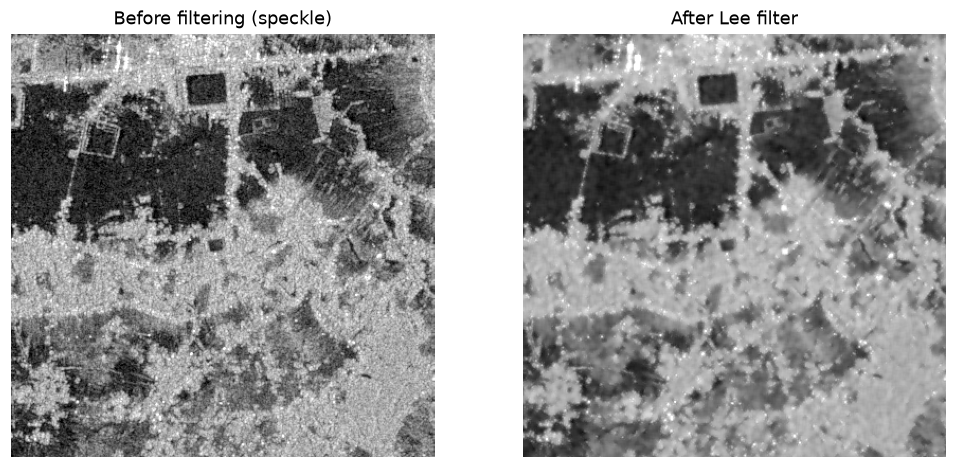

In [11]:
# Zoom into the centre of the image to see the difference
r0, c0 = pre_vv.shape[0] // 2, pre_vv.shape[1] // 2
win = np.s_[max(r0-200, 0):r0+200, max(c0-200, 0):c0+200]

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].imshow(post_vv[win],   cmap="gray", vmin=-25, vmax=0); axes[0].set_title("Before filtering (speckle)")
axes[1].imshow(post_vv_f[win], cmap="gray", vmin=-25, vmax=0); axes[1].set_title("After Lee filter")
for ax in axes: ax.axis("off")
plt.savefig(f"{OUT_DIR}/03_speckle_filter.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Change detection

We subtract the pre-flood image from the flood image:

$$\Delta\sigma^0 = \sigma^0_{flood} - \sigma^0_{pre} \quad \text{(in dB)}$$

Because dB is a log scale, this difference is the same as the **log-ratio** of the two images.

| Δ value | Meaning |
|---|---|
| close to 0 | no change |
| strongly negative | backscatter dropped → **possible new water** |
| positive | backscatter increased (e.g. flooded vegetation, crop growth) |

A drop of **3 dB** means the returned signal fell to **half**.

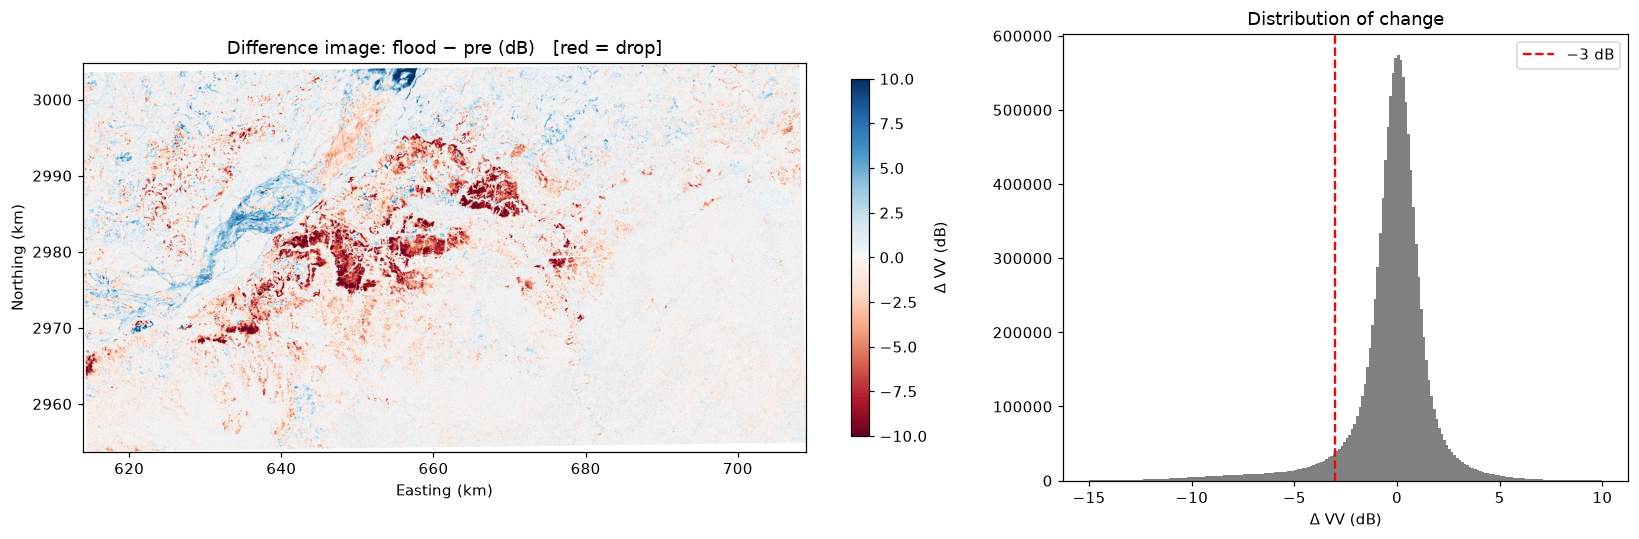

In [12]:
diff = post_vv_f - pre_vv_f

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.6, 1]})
im = axes[0].imshow(diff, cmap="RdBu", vmin=-10, vmax=10, extent=EXTENT)
axes[0].set_title("Difference image: flood − pre (dB)   [red = drop]")
axes[0].set_xlabel("Easting (km)"); axes[0].set_ylabel("Northing (km)")
fig.colorbar(im, ax=axes[0], shrink=0.8, label="Δ VV (dB)")

axes[1].hist(diff[np.isfinite(diff)], bins=200, range=(-15, 10), color="grey")
axes[1].axvline(-3, color="red", ls="--", label="−3 dB")
axes[1].set_xlabel("Δ VV (dB)"); axes[1].set_title("Distribution of change")
axes[1].legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/04_difference.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Thresholds: which pixels are flooded?

A pixel is classified as **flooded** when **both** are true:

1. **It is dark like water in the flood image** (VV below a water threshold). We find this threshold automatically with **Otsu's method**, which picks the value that best separates the two humps of the histogram.
2. **It became darker** than before (Δ below −3 dB). This removes water that was already there and dark surfaces that never changed.

Otsu water threshold: -13.72 dB
Otsu value outside the expected range -> using -18 dB instead
Using: water if VV < -18.00 dB  AND  change < -3.0 dB


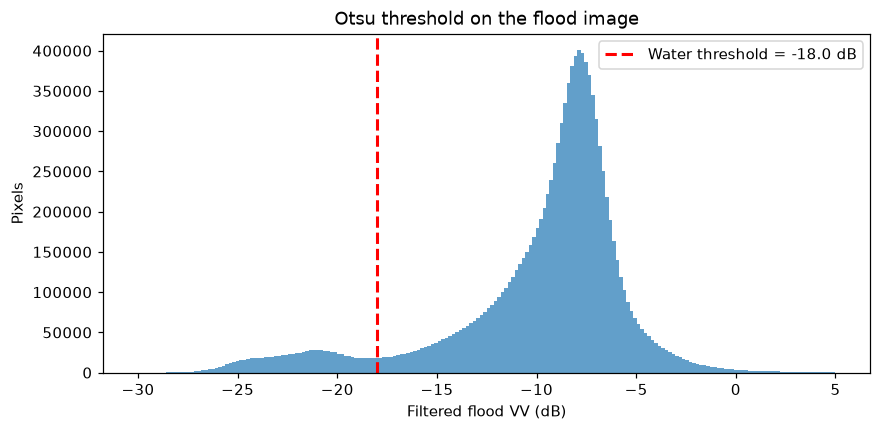

In [13]:
# --- Threshold 1: water threshold from Otsu on the filtered flood image ---
vals = post_vv_f[np.isfinite(post_vv_f)]
rng = np.random.default_rng(42)
sample = rng.choice(vals, size=min(2_000_000, vals.size), replace=False)
t_otsu = threshold_otsu(sample)
print(f"Otsu water threshold: {t_otsu:.2f} dB")

# Sanity check: open water in VV is normally between about -24 and -15 dB.
# If Otsu falls outside this range, the histogram is not clearly bimodal.
if -24 <= t_otsu <= -14:
    T_WATER = t_otsu
else:
    T_WATER = -18.0
    print("Otsu value outside the expected range -> using -18 dB instead")

# --- Threshold 2: minimum backscatter drop ---
T_DIFF = -3.0

print(f"Using: water if VV < {T_WATER:.2f} dB  AND  change < {T_DIFF} dB")

plt.figure(figsize=(9, 4))
plt.hist(vals, bins=200, range=(-30, 5), color="tab:blue", alpha=0.7)
plt.axvline(T_WATER, color="red", ls="--", lw=2, label=f"Water threshold = {T_WATER:.1f} dB")
plt.xlabel("Filtered flood VV (dB)"); plt.ylabel("Pixels")
plt.title("Otsu threshold on the flood image"); plt.legend()
plt.savefig(f"{OUT_DIR}/05_otsu.png", dpi=200, bbox_inches="tight")
plt.show()

In [14]:
water_now  = post_vv_f < T_WATER
became_dark = diff < T_DIFF
flood_raw = water_now & became_dark & valid

print(f"Raw flood pixels: {flood_raw.sum():,}  ->  {flood_raw.sum()*PIXEL_AREA/1e4:,.0f} ha")

Raw flood pixels: 350,497  ->  14,020 ha


## 7. Cleaning the flood map

The raw result contains some false alarms. We remove them step by step:

| Step | Layer | Why |
|---|---|---|
| a | **JRC permanent water** (water ≥ 50% of the time since 1984) | Rivers and lakes are not flood |
| b | **Slope > 5°** (SRTM) | Hills create radar shadow, which also looks dark |
| c | **Tiny patches** (< 10 connected pixels) | Isolated pixels are usually noise |

In [15]:
PERM_WATER_PCT = 50     # JRC occurrence %
MAX_SLOPE      = 5      # degrees
MIN_PIXELS     = 10     # 10 pixels x 400 m² = 0.4 ha at 20 m

perm_water = np.nan_to_num(jrc) >= PERM_WATER_PCT
steep      = np.nan_to_num(slope) > MAX_SLOPE

step_a = flood_raw & ~perm_water
step_b = step_a & ~steep

labels, n = ndimage.label(step_b, structure=np.ones((3, 3)))
sizes = np.bincount(labels.ravel())
keep = sizes >= MIN_PIXELS
keep[0] = False                      # label 0 = background
flood = keep[labels]

ha = lambda m: m.sum() * PIXEL_AREA / 1e4
steps = pd.DataFrame({
    "Step": ["Raw change detection", "a. minus permanent water",
             "b. minus steep slopes", "c. minus tiny patches (final)"],
    "Flooded area (ha)": [ha(flood_raw), ha(step_a), ha(step_b), ha(flood)],
}).round(0)
steps

,Step,Flooded area (ha)
0,Raw change detection,14020.0
1,a. minus permanent water,13496.0
2,b. minus steep slopes,13147.0
3,c. minus tiny patches (final),12800.0


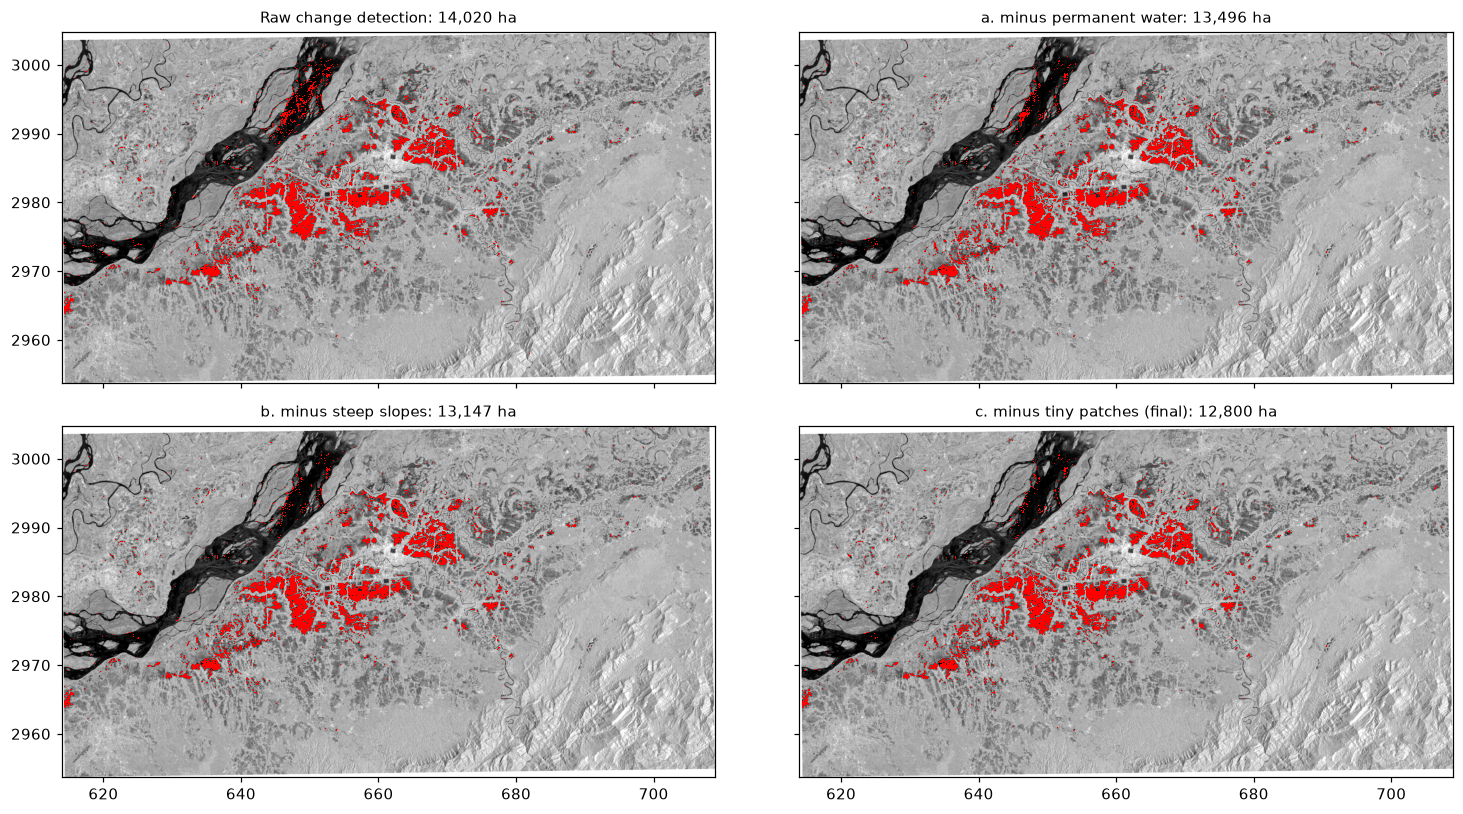

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7.5), sharex=True, sharey=True)
red = ListedColormap(["none", "red"])
for ax, m, t in zip(axes.ravel(), [flood_raw, step_a, step_b, flood], steps["Step"]):
    ax.imshow(post_vv_f, cmap="gray", vmin=-25, vmax=0, extent=EXTENT)
    ax.imshow(m.astype(int), cmap=red, vmin=0, vmax=1, extent=EXTENT, interpolation="nearest")
    ax.set_title(f"{t}: {ha(m):,.0f} ha", fontsize=10)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/06_cleaning_steps.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. How much area flooded?

In [17]:
flood_ha  = ha(flood)
flood_km2 = flood_ha / 100
aoi_km2   = valid.sum() * PIXEL_AREA / 1e6
perm_km2  = (perm_water & valid).sum() * PIXEL_AREA / 1e6

print(f"Study area analysed      : {aoi_km2:,.0f} km²")
print(f"Permanent water (rivers) : {perm_km2:,.0f} km²")
print(f"FLOODED AREA             : {flood_ha:,.0f} ha  =  {flood_km2:,.1f} km²")
print(f"Share of study area      : {100*flood_km2/aoi_km2:.1f} %")

Study area analysed      : 4,707 km²
Permanent water (rivers) : 142 km²
FLOODED AREA             : 12,800 ha  =  128.0 km²
Share of study area      : 2.7 %


## 9. What got flooded? Land cover exposure

We overlay the flood map on **ESA WorldCover 2021** to see which land cover types went under water. In Upper Assam, flooded **cropland** (mostly paddy) is the key impact on livelihoods.

In [18]:
WC_CLASSES = {10: "Tree cover", 20: "Shrubland", 30: "Grassland", 40: "Cropland",
              50: "Built-up", 60: "Bare / sparse", 80: "Permanent water",
              90: "Herbaceous wetland", 95: "Mangroves"}

rows = []
for code_, name in WC_CLASSES.items():
    cls = (lc == code_) & valid
    if cls.sum() == 0:
        continue
    rows.append({"Land cover": name,
                 "Total area (ha)": ha(cls),
                 "Flooded (ha)": ha(cls & flood),
                 "% of class flooded": 100 * (cls & flood).sum() / cls.sum()})

exposure = pd.DataFrame(rows).sort_values("Flooded (ha)", ascending=False).round(1)
exposure.to_csv(f"{OUT_DIR}/flood_by_landcover.csv", index=False)
exposure

,Land cover,Total area (ha),Flooded (ha),% of class flooded
3,Cropland,189978.7,12217.4,6.4
6,Permanent water,31743.7,314.1,1.0
2,Grassland,13889.4,136.2,1.0
7,Herbaceous wetland,871.2,64.4,7.4
0,Tree cover,223048.2,51.9,0.0
5,Bare / sparse,3167.8,15.6,0.5
1,Shrubland,203.1,0.2,0.1
4,Built-up,7761.9,0.0,0.0


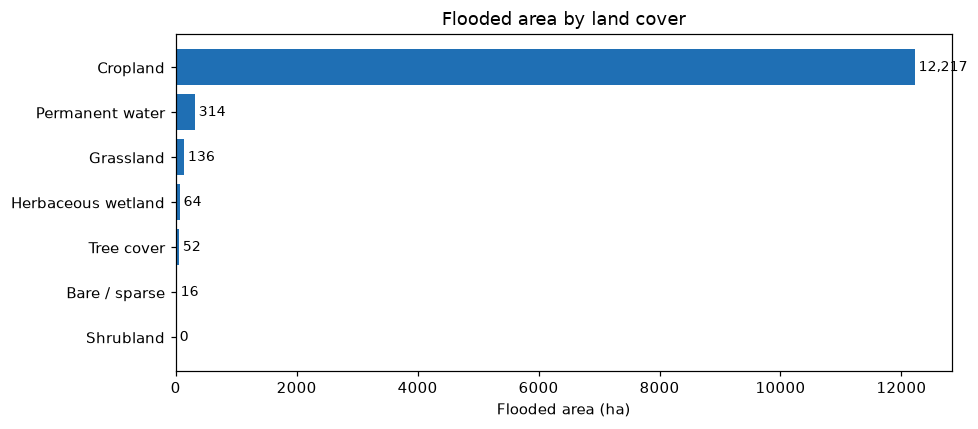

Flooded cropland: 12,217 ha


In [19]:
fig, ax = plt.subplots(figsize=(9, 4))
e = exposure[exposure["Flooded (ha)"] > 0]
ax.barh(e["Land cover"], e["Flooded (ha)"], color="#1f6fb4")
ax.invert_yaxis()
ax.set_xlabel("Flooded area (ha)")
ax.set_title("Flooded area by land cover")
for y, v in enumerate(e["Flooded (ha)"]):
    ax.text(v, y, f" {v:,.0f}", va="center", fontsize=9)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/07_landcover_exposure.png", dpi=200, bbox_inches="tight")
plt.show()

crop_ha = exposure.loc[exposure["Land cover"] == "Cropland", "Flooded (ha)"].sum()
print(f"Flooded cropland: {crop_ha:,.0f} ha")

## 10. Final flood map

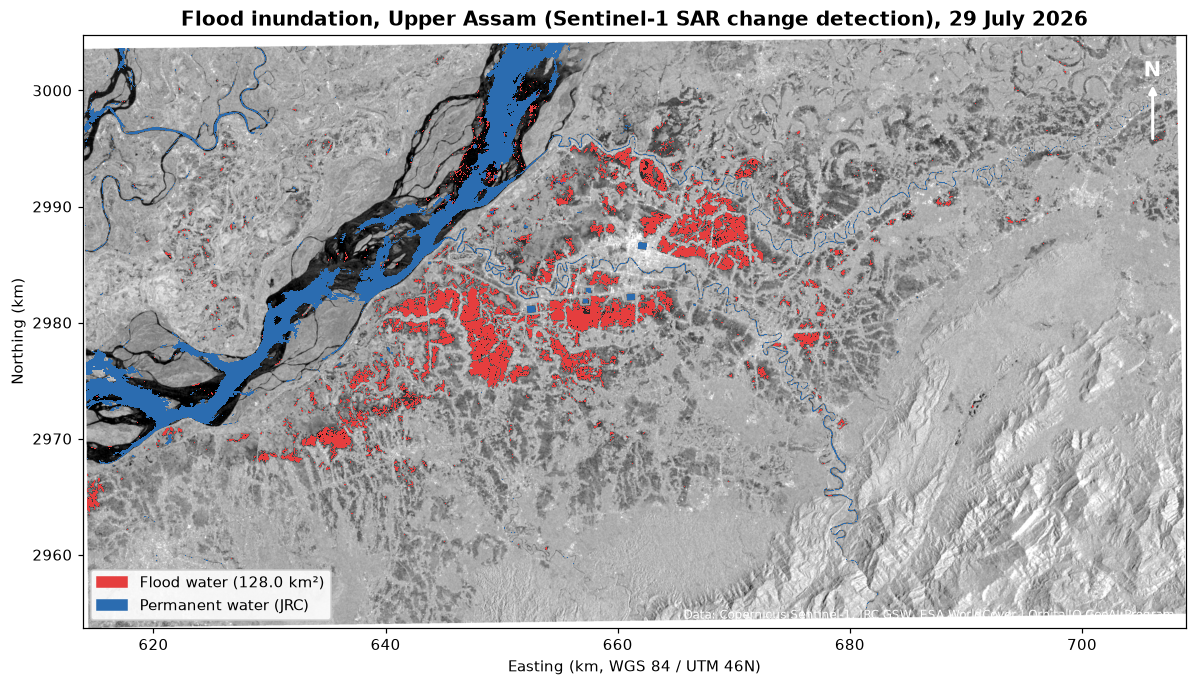

In [20]:
fig, ax = plt.subplots(figsize=(13, 7))
ax.imshow(post_vv_f, cmap="gray", vmin=-25, vmax=0, extent=EXTENT)
ax.imshow((perm_water & valid).astype(int), cmap=ListedColormap(["none", "#2b6cb0"]),
          vmin=0, vmax=1, extent=EXTENT, interpolation="nearest")
ax.imshow(flood.astype(int), cmap=ListedColormap(["none", "#e53e3e"]),
          vmin=0, vmax=1, extent=EXTENT, interpolation="nearest")

ax.legend(handles=[Patch(color="#e53e3e", label=f"Flood water ({flood_km2:,.1f} km²)"),
                   Patch(color="#2b6cb0", label="Permanent water (JRC)")],
          loc="lower left", framealpha=0.9)
ax.set_title("Flood inundation, Upper Assam (Sentinel-1 SAR change detection), 29 July 2026",
             fontsize=13, weight="bold")
ax.set_xlabel("Easting (km, WGS 84 / UTM 46N)"); ax.set_ylabel("Northing (km)")
ax.annotate("N", xy=(0.97, 0.93), xycoords="axes fraction", ha="center",
            fontsize=14, weight="bold", color="white")
ax.annotate("", xy=(0.97, 0.92), xytext=(0.97, 0.82), xycoords="axes fraction",
            arrowprops=dict(arrowstyle="-|>", color="white", lw=2))
ax.text(0.99, 0.01, "Data: Copernicus Sentinel-1, JRC GSW, ESA WorldCover | OrbitalIQ GeoAI Program",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=8, color="white")
plt.savefig(f"{OUT_DIR}/08_final_flood_map.png", dpi=250, bbox_inches="tight")
plt.show()

## 12. (Optional) Flooded area by district

If you have a district boundary shapefile for Assam, set its path below. The table shows flooded area per district.

In [ ]:
DISTRICT_FILE = "assam_districts.shp"   # change to your file
NAME_FIELD    = "DISTRICT"              # column holding the district name

if os.path.exists(DISTRICT_FILE):
    import geopandas as gpd
    from rasterio import features

    gdf = gpd.read_file(DISTRICT_FILE).to_crs(pre.rio.crs)
    ids = features.rasterize(
        ((geom, i + 1) for i, geom in enumerate(gdf.geometry)),
        out_shape=flood.shape, transform=pre.rio.transform(), fill=0, dtype="int32")

    gdf["analysed_km2"] = [((ids == i + 1) & valid).sum() * PIXEL_AREA / 1e6 for i in range(len(gdf))]
    gdf["flooded_ha"]   = [((ids == i + 1) & flood).sum() * PIXEL_AREA / 1e4 for i in range(len(gdf))]
    district_table = (gdf.loc[gdf["analysed_km2"] > 0, [NAME_FIELD, "analysed_km2", "flooded_ha"]]
                         .sort_values("flooded_ha", ascending=False).round(1))
    district_table.to_csv(f"{OUT_DIR}/flood_by_district.csv", index=False)
    display(district_table)
else:
    print(f"No district file found at '{DISTRICT_FILE}', skipping this step.")

## 13. Interpreting the results

**Compare with official reports.** Assam's disaster authority reported around 15,060 ha of crop area still submerged across the affected districts as of 2 August 2026. Our number will not match exactly. Why?
- Our study area covers only part of the affected districts
- Our flood image is from a different date than the official report
- Water levels change daily; floods rise and recede between satellite passes

**Known limitations of SAR flood mapping**
- **Urban areas:** buildings create very bright "double-bounce" returns, so flood water between buildings is often missed
- **Flooded vegetation:** water under crops or trees can make the signal *brighter*, not darker
- **Wind:** wind-roughened water can look like land
- **Dark dry surfaces:** smooth sand, tarmac and dry riverbeds can look like water
- **Paddy fields:** transplanted rice fields hold water in July, so the choice of pre-flood date matters
- **Thresholds are choices:** changing −3 dB or the water threshold changes the area

## 14. Practice exercises
1. Repeat the analysis with the **VH** band (`pre_vh_f`, `post_vh_f`). Is the flooded area larger or smaller?
2. Change `T_DIFF` to −2 dB and −5 dB. How sensitive is the flood area to this choice?
3. Change `MIN_PIXELS` to 50. What disappears from the map?
4. In GEE, change the flood window to a date in **August**. Has the water receded?
5. Use the monsoon water chart from Part A to pick the date of **maximum** flooding, and re-run the whole workflow.